<a href="https://colab.research.google.com/github/night-marionette/Pneumonia-Triage/blob/main/Pneumonia%20updated%20Triage_Results.zip" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [46]:
from google.colab import drive
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- All settings stay here at the top ----
FILE_PATH = '/content/drive/MyDrive/test_scores.csv'
ARRIVAL_MEAN_MIN = 5
READ_MEAN_MIN = 4.5
BACKLOG = 30
SHIFT_MIN = 480
CAP_MIN = 60
N_RUNS = 500
THRESHOLD = 0.5
PNEUMONIA_SHARE = 0.25

SHARES_TO_TEST = [0.10, 0.25, 0.60]
CAPS_TO_TEST = [30, 60, 120]

# Numbers from Night's evaluation cell. Fill them in when Night says "final", or leave as None.
NIGHT_MISSED = None
NIGHT_FALSE_ALARMS = None

# ---- Connect Drive and load Night's scores ----
drive.mount('/content/drive')
scores = pd.read_csv(FILE_PATH)

# ---- Check the file format ----
assert {'id', 'true_label', 'score'}.issubset(scores.columns), "Missing columns"
assert scores[['id', 'true_label', 'score']].notna().all().all(), "Missing values"
assert scores['true_label'].isin([0, 1]).all(), "Labels must be 0 or 1"
assert scores['score'].between(0, 1).all(), "Scores must be between 0 and 1"

# ---- Count scans and mistakes ----
normal = scores['true_label'] == 0
pneumonia = scores['true_label'] == 1
flagged = scores['score'] >= THRESHOLD

missed_count = (pneumonia & ~flagged).sum()
false_alarm_count = (normal & flagged).sum()

print("Total scans:", len(scores))
print("Normal scans:", normal.sum())
print("Pneumonia scans:", pneumonia.sum())
print("Missed cases (threshold", THRESHOLD, "):", missed_count)
print("False alarms (threshold", THRESHOLD, "):", false_alarm_count)

assert len(scores) == 624, "Expected 624 scans"
assert normal.sum() == 234, "Expected 234 normal scans"
assert pneumonia.sum() == 390, "Expected 390 pneumonia scans"

# ---- Compare with Night's numbers, when you have filled them in ----
if NIGHT_MISSED is not None:
    assert missed_count == NIGHT_MISSED, "Missed count does not match Night's number"
if NIGHT_FALSE_ALARMS is not None:
    assert false_alarm_count == NIGHT_FALSE_ALARMS, "False alarms do not match Night's number"

print("\nFile format is OK.")
if NIGHT_MISSED is None or NIGHT_FALSE_ALARMS is None:
    print("Now compare the missed cases and false alarms above with Night's evaluation cell. They must match.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total scans: 624
Normal scans: 234
Pneumonia scans: 390
Missed cases (threshold 0.5 ): 2
False alarms (threshold 0.5 ): 119

File format is OK.
Now compare the missed cases and false alarms above with Night's evaluation cell. They must match.


# Main chart
When the model misses a sick child, how long does that child wait? Each bar is the longest wait of a missed pneumonia scan, averaged over the shifts that had a missed scan. The black diamond is the worst single shift.

In [47]:
# Two pools of scores from the CSV: one for pneumonia scans, one for normal scans
pneu_pool = scores[scores['true_label'] == 1]['score'].values
normal_pool = scores[scores['true_label'] == 0]['score'].values


def make_scans(seed, share=PNEUMONIA_SHARE):
    rng = np.random.default_rng(seed)   # the same seed gives the same shift

    # 1. Arrival times: the backlog arrives at minute 0
    arrivals = [0.0] * BACKLOG
    t = 0.0
    while True:
        t = t + rng.exponential(ARRIVAL_MEAN_MIN)   # random gap until the next scan
        if t > SHIFT_MIN:                           # the shift is over
            break
        arrivals.append(t)

    n = len(arrivals)

    # 2. True labels: each scan is pneumonia with probability = share
    labels = (rng.random(n) < share).astype(int)

    # 3. Scores: pneumonia scans take a score from the pneumonia pool, normal ones from the normal pool
    scan_scores = np.where(labels == 1,
                           rng.choice(pneu_pool, n),
                           rng.choice(normal_pool, n))

    # 4. Reading times: random, mean READ_MEAN_MIN
    read_times = rng.exponential(READ_MEAN_MIN, n)

    return pd.DataFrame({
        'arrival': arrivals,
        'true_label': labels,
        'score': scan_scores,
        'read_time': read_times
    })


def run_queue(shift, rule, cap=CAP_MIN):
    arrival = shift['arrival'].values
    label = shift['true_label'].values
    score = shift['score'].values
    read_time = shift['read_time'].values

    n = len(shift)
    done = np.zeros(n, dtype=bool)   # which scans have been read
    waits = np.zeros(n)              # wait time of each scan
    time = 0.0                       # the clock, in minutes

    while not done.all():
        # Scans that have arrived and are not read yet
        waiting = np.where((arrival <= time) & (~done))[0]

        # If nobody is waiting, jump the clock to the next arrival
        if len(waiting) == 0:
            time = arrival[~done].min()
            continue

        # The rule picks the next scan
        if rule == 'FIFO':
            chosen = waiting[np.argmin(arrival[waiting])]        # oldest first

        elif rule == 'SCORE':
            chosen = waiting[np.argmax(score[waiting])]          # highest score first

        elif rule == 'SCORE+CAP':
            over_cap = waiting[(time - arrival[waiting]) > cap]  # waited more than the cap
            if len(over_cap) > 0:
                chosen = over_cap[np.argmin(arrival[over_cap])]  # oldest of those first
            else:
                chosen = waiting[np.argmax(score[waiting])]      # otherwise highest score

        elif rule == 'PERFECT':
            pneumonia = waiting[label[waiting] == 1]
            if len(pneumonia) > 0:
                chosen = pneumonia[np.argmin(arrival[pneumonia])]   # true pneumonia first
            else:
                chosen = waiting[np.argmin(arrival[waiting])]

        # The doctor reads the chosen scan
        waits[chosen] = time - arrival[chosen]   # wait = start of reading minus arrival
        time = time + read_time[chosen]
        done[chosen] = True

    return waits


def summarize(shift, waits):
    is_pneu = shift['true_label'].values == 1
    is_missed = is_pneu & (shift['score'].values < THRESHOLD)
    is_normal = ~is_pneu

    result = {}
    result['pneu_avg_wait'] = waits[is_pneu].mean() if is_pneu.any() else np.nan
    result['pneu_p95_wait'] = np.percentile(waits[is_pneu], 95) if is_pneu.any() else np.nan
    result['missed_count'] = is_missed.sum()
    result['missed_avg_wait'] = waits[is_missed].mean() if is_missed.any() else np.nan
    result['missed_max_wait'] = waits[is_missed].max() if is_missed.any() else np.nan
    result['normal_avg_wait'] = waits[is_normal].mean() if is_normal.any() else np.nan
    return result


test_shift = make_scans(seed=1)
print('Scans in this shift:', len(test_shift))
print('Scans at minute 0 (backlog):', (test_shift['arrival'] == 0).sum())
print('make_scans, run_queue and summarize are ready')

Scans in this shift: 118
Scans at minute 0 (backlog): 30
make_scans, run_queue and summarize are ready


In [48]:
RULES = ['FIFO', 'SCORE', 'SCORE+CAP', 'PERFECT']


def run_experiment(share=PNEUMONIA_SHARE, cap=CAP_MIN, n_runs=N_RUNS):
    rows = []
    for seed in range(n_runs):
        shift = make_scans(seed, share)          # ONE set of scans for this run
        for rule in RULES:
            waits = run_queue(shift, rule, cap)  # every rule uses the same scans
            row = summarize(shift, waits)
            row['rule'] = rule
            row['run'] = seed
            rows.append(row)
    return pd.DataFrame(rows)


# Run with the base settings
results = run_experiment()

cols = ['pneu_avg_wait', 'pneu_p95_wait', 'missed_avg_wait',
        'missed_max_wait', 'normal_avg_wait']

average = results.groupby('rule')[cols].mean().loc[RULES].round(1)
low = results.groupby('rule')[cols].quantile(0.05).loc[RULES].round(1)
high = results.groupby('rule')[cols].quantile(0.95).loc[RULES].round(1)

print('results is ready:', len(results), 'rows')
print()
print('AVERAGE across', N_RUNS, 'runs (minutes)')
print(average)
print()
print('5th percentile across runs (low end of the spread)')
print(low)
print()
print('95th percentile across runs (high end of the spread)')
print(high)
print()

fifo_runs = results[results['rule'] == 'FIFO']
print('Average number of missed pneumonia scans per shift:', round(fifo_runs['missed_count'].mean(), 2))
print('Runs with at least one missed scan:', (fifo_runs['missed_count'] > 0).sum(), 'of', N_RUNS)

results is ready: 2000 rows

AVERAGE across 500 runs (minutes)
           pneu_avg_wait  pneu_p95_wait  missed_avg_wait  missed_max_wait  \
rule                                                                        
FIFO               101.1          148.6             99.2            101.8   
SCORE               12.4           44.5             92.9             96.5   
SCORE+CAP           81.3          142.7            110.1            112.2   
PERFECT              9.0           27.3              8.8              9.2   

           normal_avg_wait  
rule                        
FIFO                 101.1  
SCORE                130.2  
SCORE+CAP            107.7  
PERFECT              131.9  

5th percentile across runs (low end of the spread)
           pneu_avg_wait  pneu_p95_wait  missed_avg_wait  missed_max_wait  \
rule                                                                        
FIFO                43.4           91.6             21.4             21.4   
SCORE            

In [49]:
print('scores:', 'scores' in globals())
print('make_scans:', 'make_scans' in globals())
print('run_queue:', 'run_queue' in globals())
print('RULES:', 'RULES' in globals())
print('results:', 'results' in globals())

scores: True
make_scans: True
run_queue: True
RULES: True
results: True


In [50]:
import os
root = '/content/drive/MyDrive'

print('Top of My Drive:')
for name in sorted(os.listdir(root)):
    print('  ', name)

print()
print('Looking for test_scores.csv ...')
found = []
if os.path.exists(root + '/test_scores.csv'):
    found.append(root + '/test_scores.csv')
for name in os.listdir(root):
    sub = root + '/' + name
    if os.path.isdir(sub):
        try:
            if 'test_scores.csv' in os.listdir(sub):
                found.append(sub + '/test_scores.csv')
        except Exception:
            pass
print('Found:', found)

Top of My Drive:
   CV_PAVLO.zip
   Colab Notebooks
   Pillars of a Strong State Presentation.pptx
   Untitled document (1).gdoc
   Untitled document (2).gdoc
   Untitled document (3).gdoc
   Untitled document (4).gdoc
   Untitled document (5).gdoc
   Untitled document.gdoc
   test_scores.csv

Looking for test_scores.csv ...
Found: ['/content/drive/MyDrive/test_scores.csv']


In [51]:
import os
root = '/content/drive/MyDrive'
print('Top of My Drive:', sorted(os.listdir(root)))

found = []
for name in os.listdir(root):
    sub = root + '/' + name
    if os.path.isdir(sub):
        try:
            if 'test_scores.csv' in os.listdir(sub):
                found.append(sub + '/test_scores.csv')
        except Exception:
            pass
print('Found:', found)

Top of My Drive: ['CV_PAVLO.zip', 'Colab Notebooks', 'Pillars of a Strong State Presentation.pptx', 'Untitled document (1).gdoc', 'Untitled document (2).gdoc', 'Untitled document (3).gdoc', 'Untitled document (4).gdoc', 'Untitled document (5).gdoc', 'Untitled document.gdoc', 'test_scores.csv']
Found: []


In [52]:
import os, time, hashlib

path = FILE_PATH
print('Size (bytes):', os.path.getsize(path))
print('Last saved (UTC):', time.asctime(time.gmtime(os.path.getmtime(path))))
with open(path, 'rb') as f:
    print('Fingerprint:', hashlib.md5(f.read()).hexdigest())

Size (bytes): 10291
Last saved (UTC): Sat Nov 14 15:06:42 2026
Fingerprint: 9d9a7f07ba09221aa65c2b31407a55c3


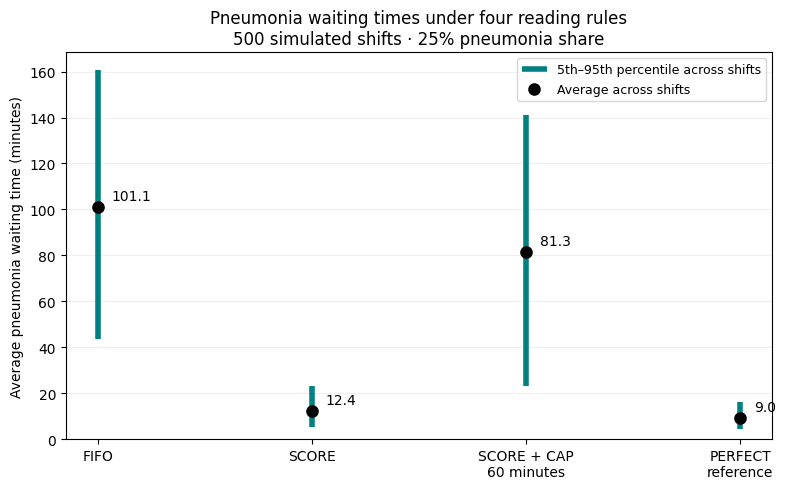

In [53]:
# Compare average pneumonia waits and the variation across shifts.
rules = ['FIFO', 'SCORE', 'SCORE+CAP', 'PERFECT']
labels = ['FIFO', 'SCORE', 'SCORE + CAP\n60 minutes', 'PERFECT\nreference']

group = results.groupby('rule')['pneu_avg_wait']

means = group.mean().reindex(rules)
low = group.quantile(0.05).reindex(rules)
high = group.quantile(0.95).reindex(rules)

x = np.arange(len(rules))

fig, ax = plt.subplots(figsize=(8, 5))

# Each vertical line shows the 5th–95th percentile across shifts.
ax.vlines(x, low, high, color='teal', linewidth=4,
          label='5th–95th percentile across shifts')

# Each dot shows the average across shifts.
ax.scatter(x, means, color='black', s=65, zorder=3,
           label='Average across shifts')

for position, value in zip(x, means):
    ax.annotate(f'{value:.1f}', (position, value),
                xytext=(10, 5), textcoords='offset points')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Average pneumonia waiting time (minutes)')
ax.set_title('Pneumonia waiting times under four reading rules\n'
             '500 simulated shifts · 25% pneumonia share')
ax.set_ylim(bottom=0)
ax.grid(axis='y', alpha=0.2)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('/content/chart1_pneumonia_wait.png', dpi=200)
plt.show()

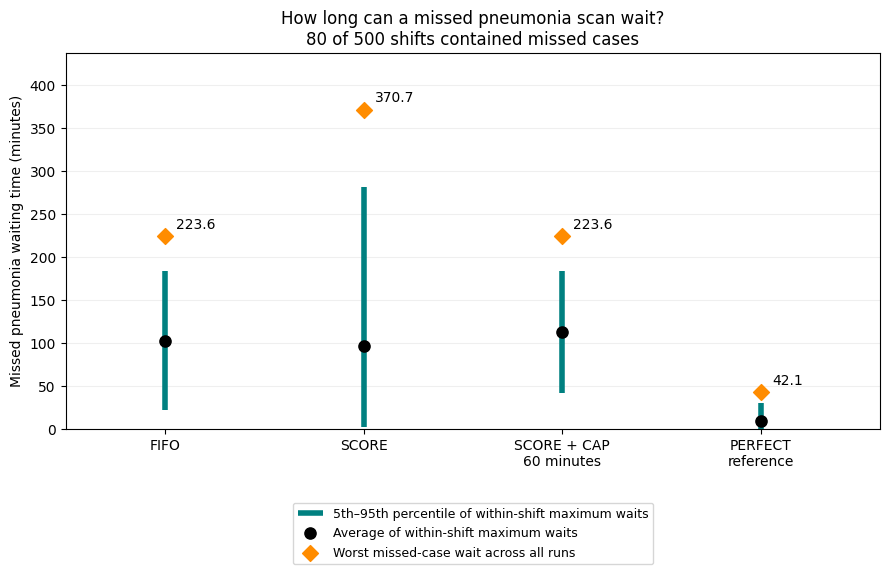

Finished: 10% pneumonia share
Finished: 25% pneumonia share
Finished: 60% pneumonia share


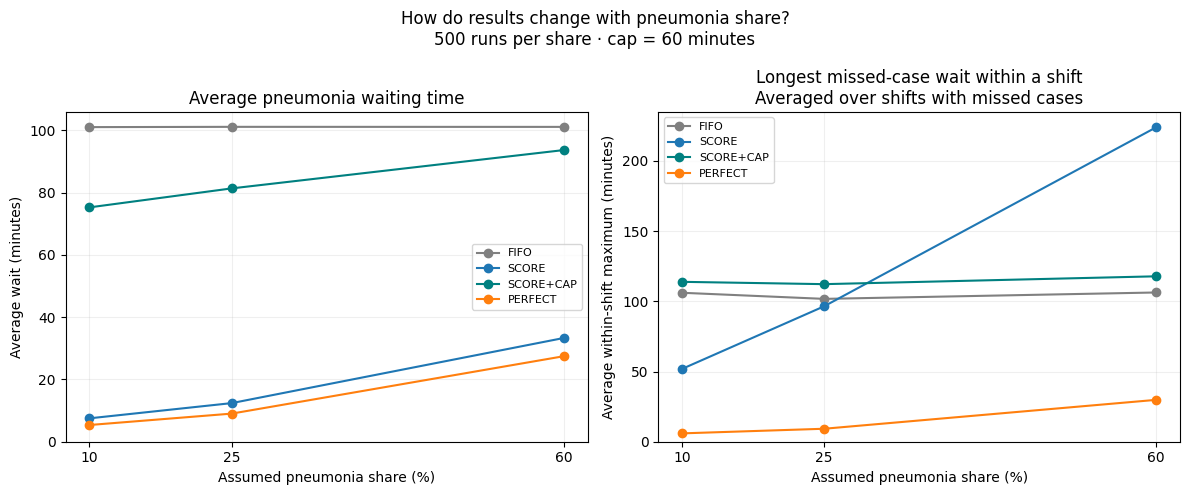


Shifts containing missed cases:
10% pneumonia: 26 of 500
25% pneumonia: 80 of 500
60% pneumonia: 166 of 500


In [54]:
import numpy as np
import matplotlib.pyplot as plt

assert 'results' in globals(), "Run the simulation cell first."

rules = ['FIFO', 'SCORE', 'SCORE+CAP', 'PERFECT']
labels = ['FIFO', 'SCORE', 'SCORE + CAP\n60 minutes',
          'PERFECT\nreference']

missed_results = results[results['missed_count'] > 0]
assert not missed_results.empty, "No shifts contained missed cases."

group = missed_results.groupby('rule')['missed_max_wait']

means = group.mean().reindex(rules)
low = group.quantile(0.05).reindex(rules)
high = group.quantile(0.95).reindex(rules)
worst = group.max().reindex(rules)

n_with_missed = missed_results['run'].nunique()
n_total = results['run'].nunique()
x = np.arange(len(rules))

fig, ax = plt.subplots(figsize=(9, 6))

ax.vlines(x, low, high, color='teal', linewidth=4,
          label='5th–95th percentile of within-shift maximum waits')

ax.scatter(x, means, color='black', s=65, zorder=3,
           label='Average of within-shift maximum waits')

ax.scatter(x, worst, color='darkorange', marker='D', s=65,
           zorder=3, label='Worst missed-case wait across all runs')

for position, value in zip(x, worst):
    ax.annotate(f'{value:.1f}', (position, value),
                xytext=(8, 6), textcoords='offset points')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlim(-0.5, 3.6)
ax.set_ylim(0, max(1, worst.max() * 1.18))
ax.set_ylabel('Missed pneumonia waiting time (minutes)')
ax.set_title(
    'How long can a missed pneumonia scan wait?\n'
    f'{n_with_missed} of {n_total} shifts contained missed cases'
)
ax.grid(axis='y', alpha=0.2)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18),
          fontsize=9)

plt.tight_layout()
plt.savefig('/content/chart2_missed_wait.png',
            dpi=200, bbox_inches='tight')
plt.show()
# Repeat the experiment with three pneumonia shares.
shares = [0.10, 0.25, 0.60]
rules = ['FIFO', 'SCORE', 'SCORE+CAP', 'PERFECT']

share_parts = []

for share in shares:
    part = run_experiment(
        share=share,
        cap=CAP_MIN,
        n_runs=N_RUNS
    )
    part['share'] = share
    share_parts.append(part)
    print(f"Finished: {share:.0%} pneumonia share")

share_results = pd.concat(share_parts, ignore_index=True)

# Calculate the average results for each share and rule.
pneumonia_wait = (
    share_results.groupby(['share', 'rule'])['pneu_avg_wait']
    .mean().unstack('rule').reindex(index=shares, columns=rules)
)

missed_wait = (
    share_results.groupby(['share', 'rule'])['missed_max_wait']
    .mean().unstack('rule').reindex(index=shares, columns=rules)
)

colors = {
    'FIFO': 'gray',
    'SCORE': 'tab:blue',
    'SCORE+CAP': 'teal',
    'PERFECT': 'tab:orange'
}

x = np.array(shares) * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for rule in rules:
    axes[0].plot(
        x, pneumonia_wait[rule],
        marker='o', color=colors[rule], label=rule
    )
    axes[1].plot(
        x, missed_wait[rule],
        marker='o', color=colors[rule], label=rule
    )

axes[0].set_title('Average pneumonia waiting time')
axes[0].set_ylabel('Average wait (minutes)')

axes[1].set_title('Longest missed-case wait within a shift\n'
                  'Averaged over shifts with missed cases')
axes[1].set_ylabel('Average within-shift maximum (minutes)')

for ax in axes:
    ax.set_xlabel('Assumed pneumonia share (%)')
    ax.set_xticks(x)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle(
    f'How do results change with pneumonia share?\n'
    f'{N_RUNS} runs per share · cap = {CAP_MIN} minutes'
)

plt.tight_layout()
plt.savefig('/content/chart3_pneumonia_shares.png',
            dpi=200, bbox_inches='tight')
plt.show()

# Count contributing shifts for the missed-case chart.
fifo = share_results[share_results['rule'] == 'FIFO']
counts = fifo.groupby('share')['missed_count'].apply(
    lambda values: (values > 0).sum()
)

print("\nShifts containing missed cases:")
for share in shares:
    print(f"{share:.0%} pneumonia: {counts.loc[share]} of {N_RUNS}")

In [55]:
# Compare caps using the same scans for every setting within each run.
settings = [
    ('FIFO', None),
    ('SCORE', None),
    ('SCORE+CAP', 30),
    ('SCORE+CAP', 60),
    ('SCORE+CAP', 120)
]

cap_rows = []

for seed in range(N_RUNS):
    shift = make_scans(seed, share=PNEUMONIA_SHARE)

    for rule, cap in settings:
        name = rule if cap is None else f'CAP {cap}'

        waits = run_queue(
            shift,
            rule,
            cap=CAP_MIN if cap is None else cap
        )

        row = summarize(shift, waits)
        row['setting'] = name
        row['run'] = seed
        cap_rows.append(row)

cap_results = pd.DataFrame(cap_rows)
order = ['FIFO', 'SCORE', 'CAP 30', 'CAP 60', 'CAP 120']

metrics = {
    'pneu_avg_wait': 'Pneumonia: average wait',
    'missed_avg_wait': 'Missed: average wait',
    'missed_max_wait': 'Missed: within-shift maximum',
    'normal_avg_wait': 'Normal: average wait'
}

group = cap_results.groupby('setting')
table = pd.DataFrame(index=order)

# Each cell shows the mean and the 5th–95th-percentile spread.
for column, title in metrics.items():
    mean = group[column].mean().reindex(order)
    low = group[column].quantile(0.05).reindex(order)
    high = group[column].quantile(0.95).reindex(order)

    table[title] = [
        f'{m:.1f} [{lo:.1f}–{hi:.1f}]'
        for m, lo, hi in zip(mean, low, high)
    ]

# Keep the single worst observed wait separate from the averages.
table['Missed: worst across all runs'] = (
    group['missed_max_wait'].max().reindex(order).round(1)
)

print(f'Cap comparison: {PNEUMONIA_SHARE:.0%} pneumonia share')
print('Minutes: mean [5th–95th percentile across runs]')
print('Missed-case statistics exclude shifts without missed cases.')
display(table)

fifo = cap_results[cap_results['setting'] == 'FIFO']
n_with_missed = (fifo['missed_count'] > 0).sum()
print(f'Shifts containing missed cases: {n_with_missed} of {N_RUNS}')

table.to_csv('/content/cap_comparison.csv', index_label='Setting')
print('Saved: cap_comparison.csv')

Cap comparison: 25% pneumonia share
Minutes: mean [5th–95th percentile across runs]
Missed-case statistics exclude shifts without missed cases.


,Pneumonia: average wait,Missed: average wait,Missed: within-shift maximum,Normal: average wait,Missed: worst across all runs
FIFO,101.1 [43.4–160.7],99.2 [21.4–181.6],101.8 [21.4–183.1],101.1 [44.4–158.2],223.6
SCORE,12.4 [5.3–23.2],92.9 [1.4–280.1],96.5 [1.4–280.8],130.2 [56.8–208.6],370.7
CAP 30,90.2 [33.4–149.9],104.0 [37.0–181.6],106.4 [37.0–183.1],104.6 [48.0–160.8],223.6
CAP 60,81.3 [23.3–140.9],110.1 [41.9–181.6],112.2 [41.9–183.1],107.7 [50.8–164.3],223.6
CAP 120,57.0 [10.8–128.2],126.8 [16.1–188.9],128.7 [16.1–188.9],115.6 [56.8–170.7],238.1


Shifts containing missed cases: 80 of 500
Saved: cap_comparison.csv


In [56]:
import os
import zipfile
from google.colab import files

# Save the numerical results behind the charts.
results.to_csv('/content/base_results.csv', index=False)
share_results.to_csv('/content/share_results.csv', index=False)
cap_results.to_csv('/content/cap_results.csv', index=False)

# Save the exact input scores used for this simulation.
scores.to_csv('/content/simulation_input_scores.csv', index=False)

# Collect the charts, summary table and detailed results.
export_names = [
    'chart1_pneumonia_wait.png',
    'chart2_missed_wait.png',
    'chart3_pneumonia_shares.png',
    'cap_comparison.csv',
    'base_results.csv',
    'share_results.csv',
    'cap_results.csv',
    'simulation_input_scores.csv'
]

# Check that every expected file exists.
for name in export_names:
    assert os.path.exists('/content/' + name), f'Missing file: {name}'

# Package everything into one downloadable ZIP.
zip_path = '/content/Pneumonia_Triage_Results.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for name in export_names:
        archive.write('/content/' + name, arcname=name)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>